# Setup

In [51]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src.config import cfg
from src.data_loader import load_data

df_raw = load_data()

2026-11-09 16:20:11,446 | INFO | src.data_loader | Données chargées : 2000 lignes x 17 colonnes


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## General structure

In [52]:
print(df_raw.shape)
df_raw.head()

(2000, 17)


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [53]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   object 
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   object 
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   object 
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 19

In [54]:
df_raw.nunique().sort_values()

Part_Time_Job                        2
Previous_Mental_Health_History       2
Mental_Health_Risk                   3
Gender                               3
Diet_Quality                         3
Physical_Activity                    3
Year_of_Study                        5
Age                                 13
Sleep_Hours                         66
Social_Media_Hours                  71
Family_Support                      82
Financial_Stress                    87
Screen_Time_Hours                   95
GPA                                182
Study_Hours_Per_Week               284
Attendance_Rate                    313
Student_ID                        2000
dtype: int64

## split the columns by type

In [55]:
num_cols = df_raw.select_dtypes(include="number").columns.drop(cfg.TARGET_COL, errors="ignore").tolist()
cat_cols = df_raw.select_dtypes(exclude="number").columns.drop(cfg.TARGET_COL, errors="ignore").tolist()
print("Numériques :", num_cols)
print("Catégorielles :", cat_cols)

Numériques : ['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']
Catégorielles : ['Student_ID', 'Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History']


# Data quality audit

## Missing values

In [56]:
missing = df_raw.isna().sum().to_frame("n_missing")
missing["pct"] = (missing["n_missing"] / len(df_raw) * 100).round(2)
missing[missing["n_missing"] > 0].sort_values("pct", ascending=False)

,n_missing,pct
Financial_Stress,91,4.55
Diet_Quality,69,3.45
Sleep_Hours,62,3.10
Social_Media_Hours,58,2.90
Family_Support,54,2.70
Attendance_Rate,47,2.35
GPA,38,1.90


## Duplicates

In [57]:
print("Doublons exacts :", df_raw.duplicated().sum())

Doublons exacts : 0


## Inconsistencies

In [58]:
for col in cat_cols:
    print(col, df_raw[col].unique())

Student_ID ['STU0001' 'STU0002' 'STU0003' ... 'STU1998' 'STU1999' 'STU2000']
Gender ['Male' 'Female' 'Non-binary']
Physical_Activity ['Moderate' 'Low' 'High']
Part_Time_Job ['No' 'Yes']
Diet_Quality ['Poor' 'Average' nan 'Good']
Previous_Mental_Health_History ['No' 'Yes']


In [59]:
df_raw[num_cols].describe().T[["min", "max"]]

,min,max
Age,17.0,29.00
Year_of_Study,1.0,5.00
Sleep_Hours,3.3,10.00
Study_Hours_Per_Week,2.4,38.30
GPA,1.5,3.66
Social_Media_Hours,2.1,10.00
Screen_Time_Hours,3.3,14.00
Financial_Stress,1.4,10.00
Family_Support,1.7,9.90
Attendance_Rate,54.4,100.00


## Outliers

In [60]:
def iqr_outliers(s: pd.Series) -> int:
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

outliers = pd.DataFrame({
    "n_outliers_iqr" : [iqr_outliers(df_raw[c]) for c in num_cols],
    "n_outliers_z3": [int((np.abs(stats.zscore(df_raw[c], nan_policy="omit")) > 3).sum()) for c in num_cols],
}, index=num_cols)
outliers

,n_outliers_iqr,n_outliers_z3
Age,4,4
Year_of_Study,0,0
Sleep_Hours,2,1
Study_Hours_Per_Week,7,4
GPA,9,4
Social_Media_Hours,20,6
Screen_Time_Hours,7,4
Financial_Stress,0,0
Family_Support,0,0
Attendance_Rate,12,9


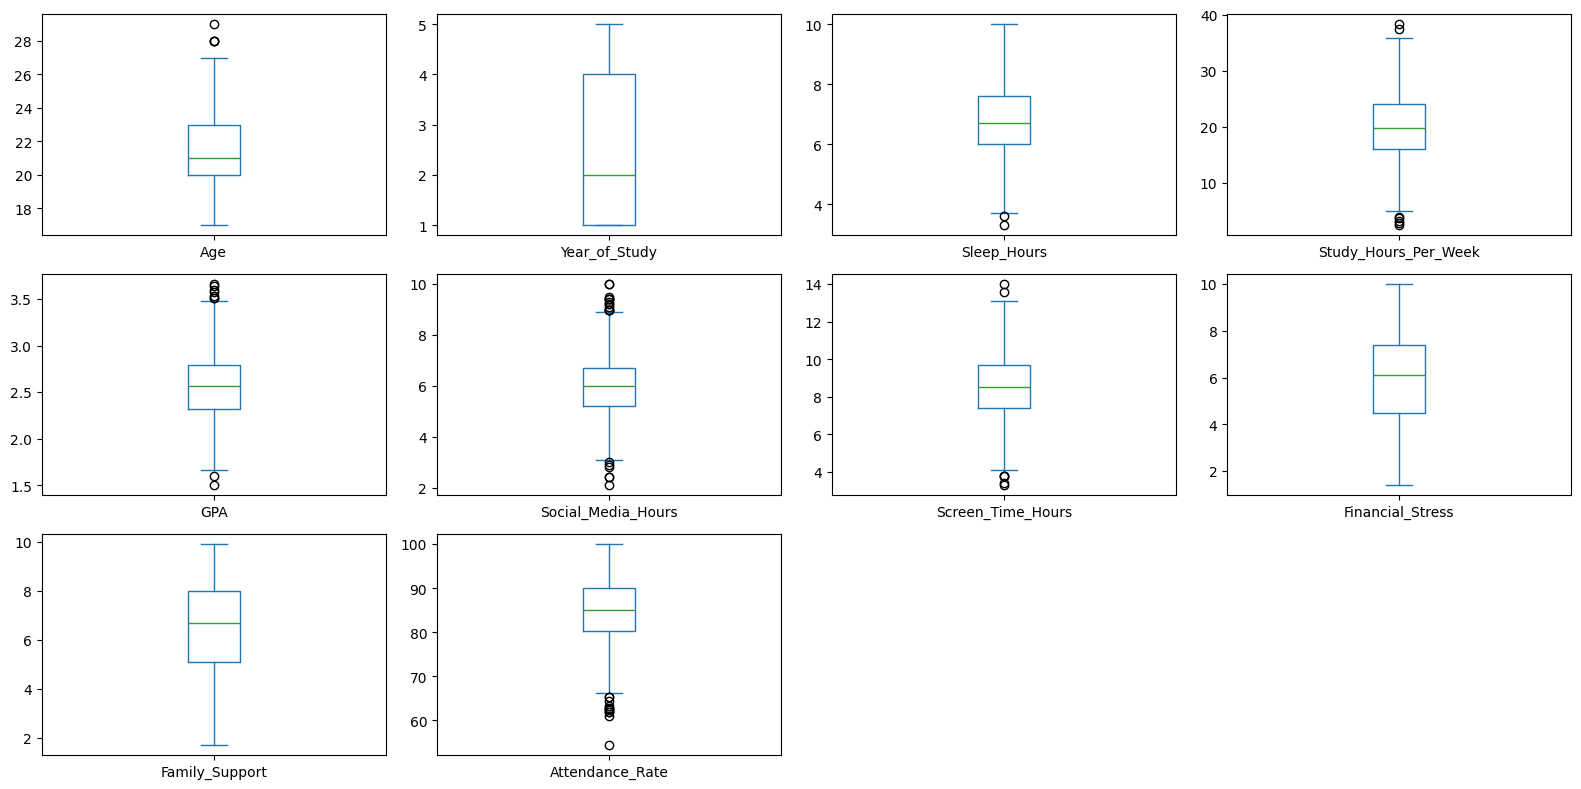

In [61]:
df_raw[num_cols].plot(kind="box", subplots=True, layout=(-1, 4), figsize=(16, 8), sharey=False)
plt.tight_layout()
plt.savefig(cfg.FIGURES_DIR / "boxplots.png")

## Descriptive statistics

In [63]:
desc = df_raw[num_cols].describe().T
desc["skew"] = df_raw[num_cols].skew()
desc

,count,mean,std,min,25%,50%,75%,max,skew
Age,2000.0,21.131500,2.139275,17.0,20.000,21.00,23.00,29.00,0.200876
Year_of_Study,2000.0,2.630000,1.316802,1.0,1.000,2.00,4.00,5.00,0.314226
Sleep_Hours,1938.0,6.758875,1.127072,3.3,6.000,6.70,7.60,10.00,0.051094
Study_Hours_Per_Week,2000.0,19.997900,5.719274,2.4,16.000,19.80,24.00,38.30,0.039271
GPA,1962.0,2.562503,0.343993,1.5,2.320,2.56,2.79,3.66,0.087445
Social_Media_Hours,1942.0,6.013955,1.153422,2.1,5.225,6.00,6.70,10.00,0.092598
Screen_Time_Hours,2000.0,8.548500,1.657571,3.3,7.400,8.50,9.70,14.00,-0.044073
Financial_Stress,1909.0,5.956260,1.893941,1.4,4.500,6.10,7.40,10.00,-0.168759
Family_Support,1946.0,6.518345,1.844639,1.7,5.100,6.70,8.00,9.90,-0.304270
Attendance_Rate,1953.0,85.080236,7.224118,54.4,80.300,85.10,90.00,100.00,-0.116483


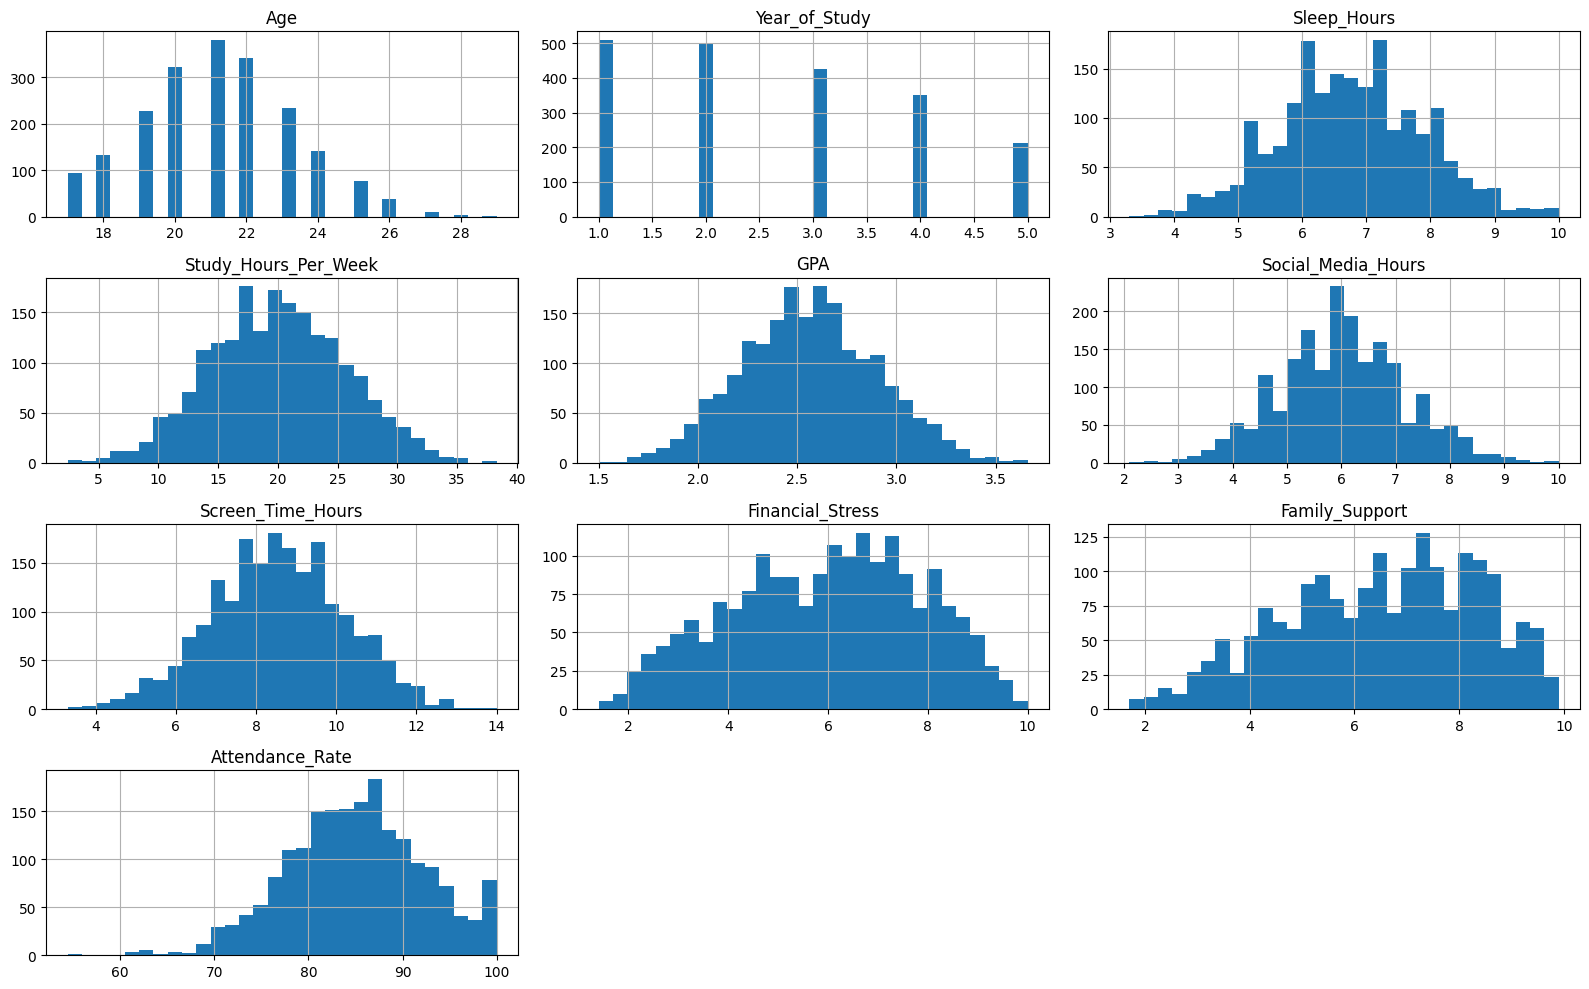

In [66]:
df_raw[num_cols].hist(bins=30, figsize=(16, 10))
plt.tight_layout()
plt.savefig(cfg.FIGURES_DIR / "histograms.png")

In [89]:
for col in cat_cols:
    print(df_raw[col].value_counts(normalize=True) * 100, "\n")

Student_ID
STU0001    0.05
STU1330    0.05
STU1343    0.05
STU1342    0.05
STU1341    0.05
           ... 
STU0662    0.05
STU0661    0.05
STU0660    0.05
STU0659    0.05
STU2000    0.05
Name: proportion, Length: 2000, dtype: float64 

Gender
Female        48.55
Male          46.60
Non-binary     4.85
Name: proportion, dtype: float64 

Physical_Activity
Moderate    45.30
Low         33.95
High        20.75
Name: proportion, dtype: float64 

Part_Time_Job
No     64.45
Yes    35.55
Name: proportion, dtype: float64 

Diet_Quality
Average    44.536510
Poor       30.398757
Good       25.064733
Name: proportion, dtype: float64 

Previous_Mental_Health_History
No     70.4
Yes    29.6
Name: proportion, dtype: float64 



## Target variable and imbalance

Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64
Mental_Health_Risk
High      34.0
Medium    33.0
Low       33.0
Name: count, dtype: float64
Ratio de déséquilibre : 1.03


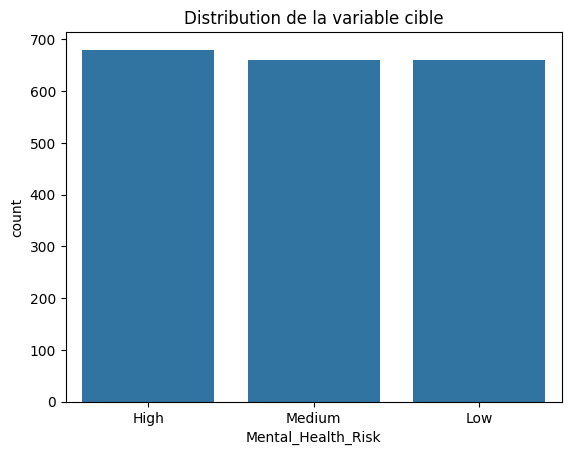

In [74]:
counts = df_raw[cfg.TARGET_COL].value_counts()
print(counts)
print((counts / len(df_raw) * 100).round(2))
print("Ratio de déséquilibre :", round(counts.max() / counts.min(), 2))

sns.countplot(data=df_raw, x=cfg.TARGET_COL, order=counts.index)
plt.title("Distribution de la variable cible")
plt.savefig(cfg.FIGURES_DIR / "target_distribution.png")


# Relationships between features and target

## Numeric features vs target

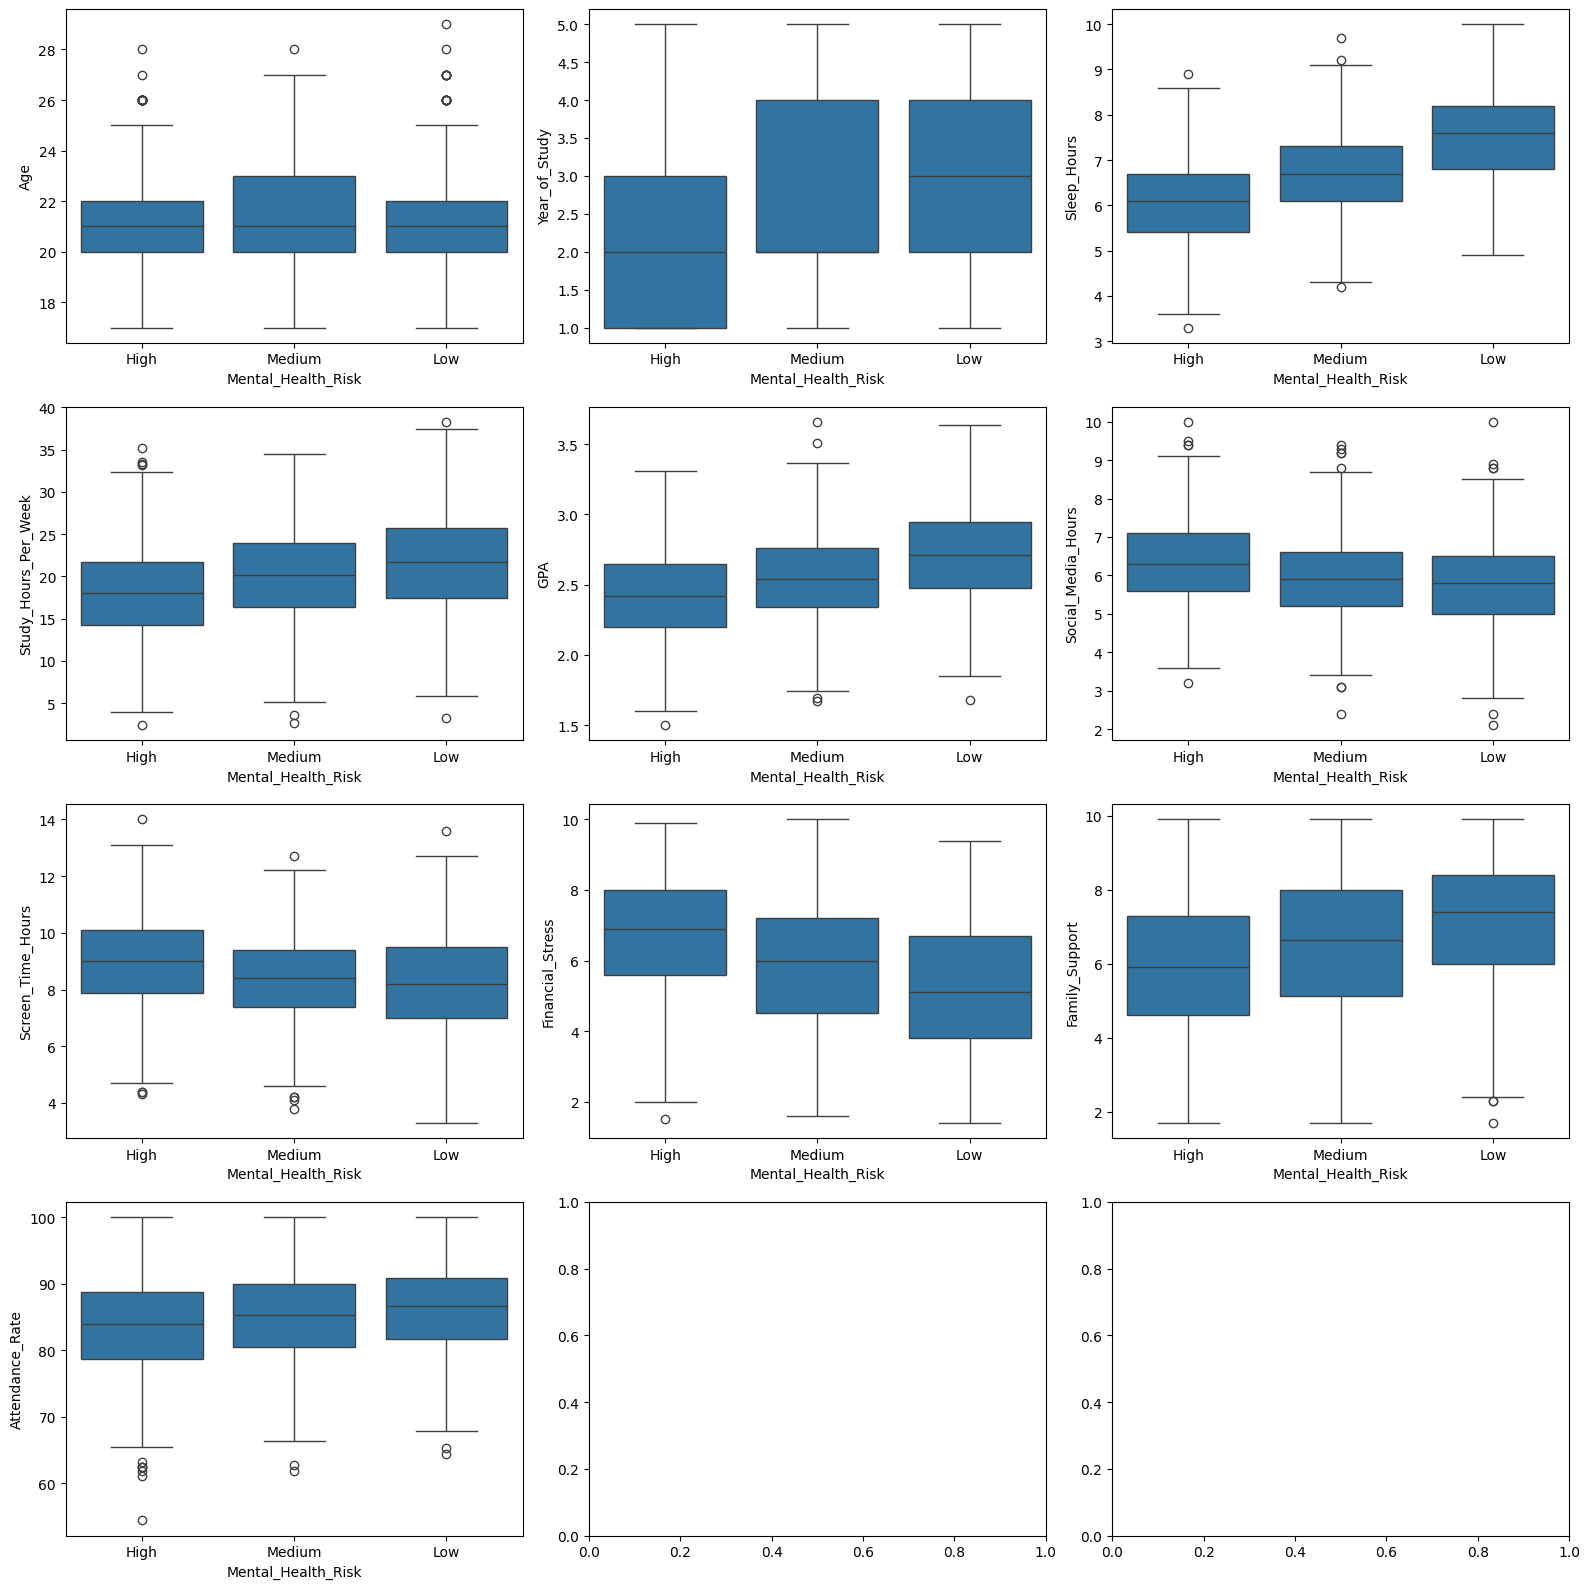

In [78]:
fig, axes = plt.subplots(nrows=(len(num_cols) + 2) // 3, ncols=3, figsize=(16, 4 * ((len(num_cols) + 2) // 3)))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(data=df_raw, x=cfg.TARGET_COL, y=col, ax=ax)
plt.tight_layout()
plt.savefig(cfg.FIGURES_DIR / "num_vs_target.png")